# Universidad de Buenos Aires
# Aprendizaje Profundo - TP3
# Cohorte 26 - 4to bimestre 2026


## **Alumno 1:** Lerner, Federico Ezequiel - a2619

## **Alumno 2:** Makk, Azul de los Angeles - a2622

## **Alumno 3:** Moguilner Reh, Nicolás Francisco - a2623

Este tercer y último TP se debe entregar hasta las **23:59hs del miércoles 21 de octubre (hora de Argentina)**.

La resolución del TP puede realizarse de forma **individual, en parejas o hasta en grupos de 3 como máximo**. Sin embargo, no se recomienda repartir las preguntas entre los integrantes, sino que todos los integrantes deben trabajar conjuntamente en la resolución de cada pregunta. De esta manera, se promueve el debate, la discusión y la construcción de una conclusión compartida sobre cómo abordar y resolver cada pregunta.

Pueden utilizar los contenidos vistos en clase y otra bibliografía que consideren que les haga falta. Si se toman ideas de fuentes externas deben ser correctamente citadas incluyendo el correspondiente link o página de libro.

ESTE TP3 EQUIVALE A UN TERCIO DE SU NOTA FINAL.

El formato de entrega debe ser un link a un notebook de google colab. Permitir acceso a gvilcamiza.ext@fi.uba.ar y **habilitar los comentarios, para poder darles el feedback**. Si no lo hacen así no se podrá dar el feedback respectivo por cada pregunta.

**El desarrollo del TP se debe hacer obligatoriamente en un notebook**, ya sea en un Google Colab o en un Jupyter Notebook para quienes quieran desarrollarlo en su propia PC local. Pero no se aceptarán archivos `.py` o links a repos de github con múltiples archivos. El entregable debe ser un link a un único archivo en formato `.ipynb`.

El envío **se realizará en el siguiente link de google forms: [link](https://forms.gle/v2e6LA4umZ6VM8sQ8)**. Tanto los resultados, gráficas, como el código y las explicaciones deben quedar guardados y visualizables en el colab.

**NO SE VALIDARÁN ENVÍOS POR CORREO, EL MÉTODO DE ENTREGA ES SOLO POR EL FORMS.**

**Consideraciones a tener en cuenta:**
- Se entregará 1 solo colab para este TP3.
- Renombrar el archivo de la siguiente manera: **PRIMERAPELLIDOALUMNO1-PRIMERAPELLIDOALUMNO2-PRIMERAPELLIDOALUMNO3-TP3-Co26.ipynb**
O en caso hacerlo individual usar: **PRIMERAPELLIDO-PRIMERNOMBRE-TP3-Co26.ipynb**
- Los códigos deben poder ejecutarse.
- **IMPORTANTE:** Los resultados, cómo el código, los gráficos, los prints y las explicaciones deben quedar guardados y visualizables en el mismo notebook.
- No ocultar celdas, todas se deben poder ver desde el inicio.
- **Prestar mucha atención a cada consigna, responder las preguntas justo debajo del enunciado que corresponda.**
- Solo se revisarán los trabajos que hayan sido enviados por el forms.

# **CLASIFICADOR DE EMOCIONES**

El objetivo de este trabajo es construir una red neuronal convolucional (CNN) utilizando Pytorch, capaz de clasificar emociones humanas a partir de imágenes faciales. El clasificador deberá identificar una de las 7 emociones básicas: alegría, tristeza, enojo, miedo, sorpresa, disgusto y seriedad. El dataset se encuentra en este link: https://drive.google.com/file/d/1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT/view?usp=sharing

Les recomiendo usar el siguiente código para poder obtener las imágenes fácilmente desde ese link. Pero son libres de descargar las imágenes como mejor les parezca.

In [1]:
import gdown
import zipfile
import os

url = "https://drive.google.com/uc?id=1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT"
output = "archivo.zip"
destino = "datos_zip"

if not os.path.exists(os.path.join(destino, "dataset_emociones")):   # si ya está descargado, no se vuelve a bajar
    gdown.download(url, output, quiet=False)
    os.makedirs(destino, exist_ok=True)
    with zipfile.ZipFile(output, 'r') as zip_ref:
        zip_ref.extractall(destino)

DATASET_ROOT_TRAIN = os.path.join(destino, 'dataset_emociones', 'train')        # en Colab: /content/datos_zip/dataset_emociones/train
DATASET_ROOT_VAL   = os.path.join(destino, 'dataset_emociones', 'validation')

In [2]:
import glob
import copy
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
def fijar_semilla(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

fijar_semilla(SEED)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
NUM_WORKERS = 2 if device.type == "cuda" else 0     # en Colab con GPU paralelizamos la carga
print("device:", device)

CLASES = sorted(os.listdir(DATASET_ROOT_TRAIN))
print("clases:", CLASES)

device: mps
clases: ['alegria', 'disgusto', 'enojo', 'miedo', 'seriedad', 'sorpresa', 'tristeza']


## 1. Preprocesamiento de Datos (2 puntos)

Antes de entrenar el modelo, se debe analizar qué tipo de preprocesamiento se debe aplicar a las imágenes. Para esto, se puede considerar uno o más aspectos como:

- Tamaño
- Relación de aspecto
- Color o escala de grises
- Cambio de dimensionalidad
- Normalización
- Balanceo de datos
- Data augmentation
- etc.

Sean criteriosos y elijan solo las técnicas que consideren pertinentes para este caso de uso en específico.

Recomendación: usar `torchvision.transforms` para facilitar el preprocesamiento. Lean su documentación si tienen dudas: https://docs.pytorch.org/vision/0.14/transforms.html



train: 12271 imágenes | validation: 3068 imágenes


,train,validation,% train,% validation
alegria,4772,1185,38.9,38.6
disgusto,717,160,5.8,5.2
enojo,705,162,5.7,5.3
miedo,281,74,2.3,2.4
seriedad,2524,680,20.6,22.2
sorpresa,1290,329,10.5,10.7
tristeza,1982,478,16.2,15.6


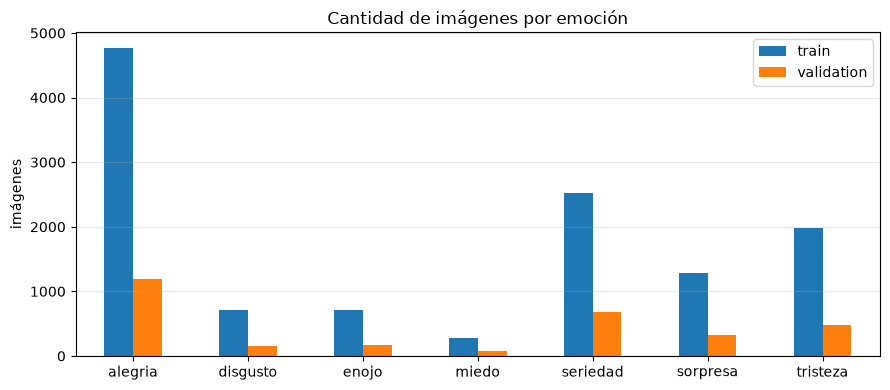

desbalance: la clase más grande tiene 17.0 veces más imágenes que la más chica


In [3]:
def cargar_split(raiz):
    """Lee todas las imágenes de una carpeta train/validation y las deja en memoria (son chicas)."""
    imagenes, etiquetas = [], []
    for i, clase in enumerate(CLASES):
        for archivo in sorted(glob.glob(os.path.join(raiz, clase, "*.jpg"))):
            with Image.open(archivo) as im:
                imagenes.append(im.convert("RGB"))
            etiquetas.append(i)
    return imagenes, np.array(etiquetas)

imgs_train, y_train = cargar_split(DATASET_ROOT_TRAIN)
imgs_val, y_val = cargar_split(DATASET_ROOT_VAL)

conteo = pd.DataFrame({"train": np.bincount(y_train), "validation": np.bincount(y_val)}, index=CLASES)
conteo["% train"] = (100 * conteo["train"] / conteo["train"].sum()).round(1)
conteo["% validation"] = (100 * conteo["validation"] / conteo["validation"].sum()).round(1)
print(f"train: {len(y_train)} imágenes | validation: {len(y_val)} imágenes")
display(conteo)

ax = conteo[["train", "validation"]].plot.bar(figsize=(9, 4), rot=0)
ax.set_title("Cantidad de imágenes por emoción"); ax.set_ylabel("imágenes"); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()
print(f"desbalance: la clase más grande tiene {conteo['train'].max() / conteo['train'].min():.1f} veces más imágenes que la más chica")

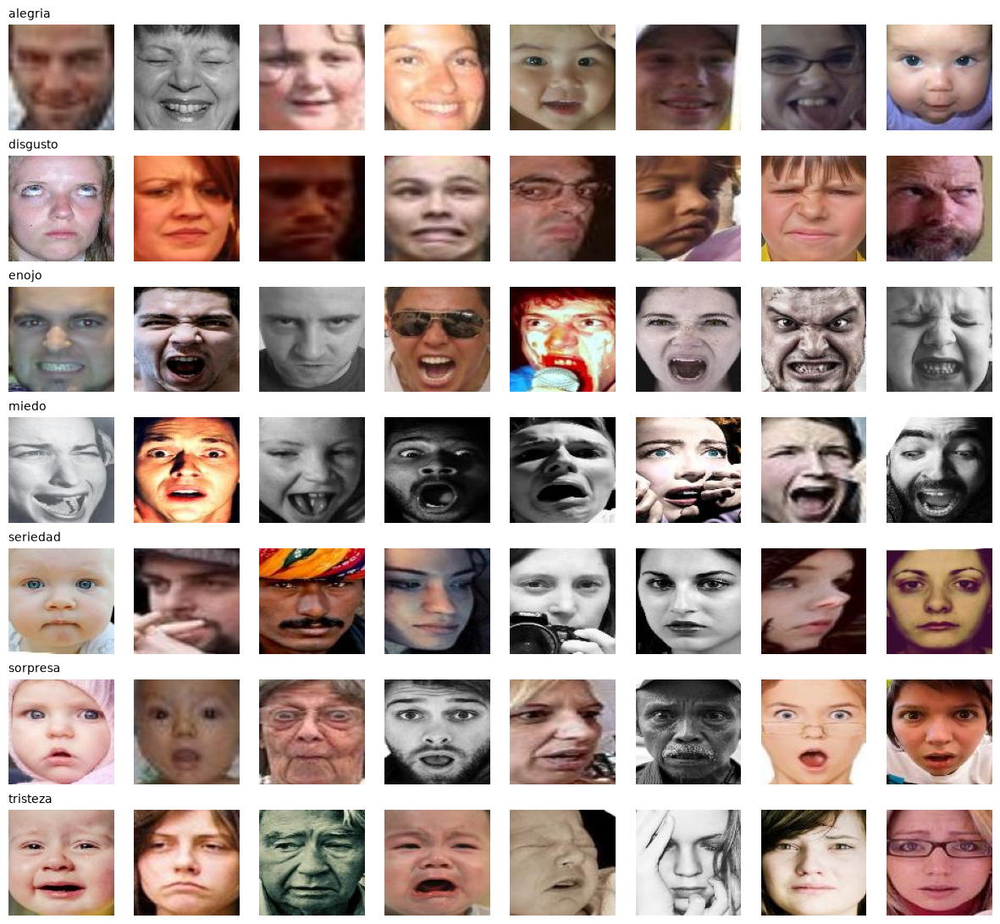

In [4]:
# Algunas imágenes de cada clase
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(CLASES), 8, figsize=(12, 11))
for i, clase in enumerate(CLASES):
    for j, k in enumerate(rng.choice(np.where(y_train == i)[0], 8, replace=False)):
        axes[i, j].imshow(imgs_train[k]); axes[i, j].axis("off")
    axes[i, 0].set_title(clase, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

In [5]:
# Tamaños, modos de color y cuántas imágenes ya vienen en escala de grises
tamanios = pd.Series([im.size for im in imgs_train + imgs_val]).value_counts()
print("tamaños (ancho, alto):", dict(tamanios))

def es_gris(im):
    a = np.asarray(im, dtype=np.int16)
    return np.abs(a[..., 0] - a[..., 1]).mean() < 1 and np.abs(a[..., 1] - a[..., 2]).mean() < 1

grises = np.array([es_gris(im) for im in imgs_train])
print(f"imágenes de train que ya son grises (los 3 canales iguales): {grises.mean():.1%}")
print("% de grises por clase:", {c: f"{grises[y_train == i].mean():.0%}" for i, c in enumerate(CLASES)})

# Media y desvío de la intensidad en gris, calculados solo con train (para normalizar)
gris_train = np.stack([np.asarray(im.convert("L"), dtype=np.float32) / 255 for im in imgs_train])
MEDIA, DESVIO = float(gris_train.mean()), float(gris_train.std())
print(f"media = {MEDIA:.4f} | desvío = {DESVIO:.4f}")
del gris_train

tamaños (ancho, alto): {(100, 100): np.int64(15339)}


imágenes de train que ya son grises (los 3 canales iguales): 13.1%
% de grises por clase: {'alegria': '8%', 'disgusto': '12%', 'enojo': '19%', 'miedo': '45%', 'seriedad': '13%', 'sorpresa': '11%', 'tristeza': '21%'}


media = 0.4816 | desvío = 0.2427


Lo primero que miramos fue cómo viene el dataset. Son 12.271 imágenes de train y 3.068 de validation, separadas en una carpeta por emoción. Por los nombres de los archivos y las cantidades, parece ser la versión básica de RAF-DB, un dataset de caras sacadas de internet. Las proporciones de cada clase son muy parecidas en train y en validation.

Lo que más salta a la vista es el desbalance: alegría tiene 4.772 imágenes de train (39%) y miedo apenas 281 (2,3%), 17 veces menos. Disgusto y enojo también son chicas, con menos del 6% cada una. Esto importa por dos lados. Por un lado, un modelo que conteste siempre "alegría" ya saca 39% de accuracy, así que la accuracy sola no alcanza y el F1 macro es la métrica que más vamos a mirar. Por otro lado, si no hacemos nada, la red va a ver 17 caras felices por cada cara de miedo y es probable que aprenda poco de las clases chicas.

En la grilla de ejemplos se ve que las imágenes ya vienen recortadas y alineadas: la cara ocupa casi todo el cuadro, con los ojos más o menos a la misma altura. Todas son de 100x100. Fuera de eso, son muy variadas: hay bebés y personas mayores, fotos movidas, con poca luz, con anteojos o con una mano tapando parte de la cara. Las expresiones suelen ser bastante exageradas (bocas muy abiertas en miedo y sorpresa, dientes a la vista en enojo).

Un detalle que nos llamó la atención: el 13% de las imágenes de train ya vienen en blanco y negro, y no de forma pareja. En miedo son el 45%, contra el 8% en alegría. Si entrenáramos en color, la red podría aprender un atajo del tipo "si la foto es gris, probablemente sea miedo", que no tiene nada que ver con la expresión y que no serviría para fotos nuevas. Esto pesó mucho en la decisión de trabajar en escala de grises.

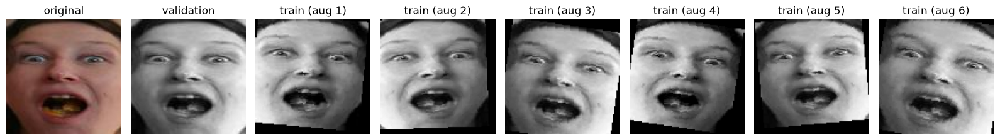

In [6]:
TAMANIO = 100

# Validation (y después las imágenes nuevas): gris, lado corto a 100 y recorte central cuadrado, tensor y normalización
transform_val = T.Compose([
    T.Grayscale(num_output_channels=1),
    T.Resize(TAMANIO),
    T.CenterCrop(TAMANIO),
    T.ToTensor(),
    T.Normalize([MEDIA], [DESVIO]),
])

# Train: lo mismo más data augmentation
transform_train = T.Compose([
    T.Grayscale(num_output_channels=1),
    T.Resize(TAMANIO),
    T.CenterCrop(TAMANIO),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.ToTensor(),
    T.Normalize([MEDIA], [DESVIO]),
])

class DatasetEmociones(Dataset):
    def __init__(self, imagenes, etiquetas, transform):
        self.imagenes, self.etiquetas, self.transform = imagenes, etiquetas, transform

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, i):
        return self.transform(self.imagenes[i]), int(self.etiquetas[i])

def armar_loader_train(transform, balanceo, seed=SEED, batch_size=64):
    ds = DatasetEmociones(imgs_train, y_train, transform)
    g = torch.Generator().manual_seed(seed)
    if balanceo == "sampler":
        # cada imagen se sortea con probabilidad inversa a la frecuencia de su clase
        pesos = 1.0 / np.bincount(y_train)[y_train]
        sampler = WeightedRandomSampler(torch.tensor(pesos, dtype=torch.double), len(y_train), replacement=True, generator=g)
        return DataLoader(ds, batch_size=batch_size, sampler=sampler, num_workers=NUM_WORKERS)
    return DataLoader(ds, batch_size=batch_size, shuffle=True, generator=g, num_workers=NUM_WORKERS)

loader_val = DataLoader(DatasetEmociones(imgs_val, y_val, transform_val), batch_size=256, num_workers=NUM_WORKERS)

# Cómo se ve una misma cara con el preprocesamiento de validation y con varias augmentations
def desnormalizar(t):
    return (t.squeeze(0) * DESVIO + MEDIA).clamp(0, 1).numpy()

ejemplo = imgs_train[int(np.where(y_train == CLASES.index("sorpresa"))[0][3])]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
axes[0].imshow(ejemplo); axes[0].set_title("original")
axes[1].imshow(desnormalizar(transform_val(ejemplo)), cmap="gray"); axes[1].set_title("validation")
torch.manual_seed(0)
for k in range(2, 8):
    axes[k].imshow(desnormalizar(transform_train(ejemplo)), cmap="gray"); axes[k].set_title(f"train (aug {k - 1})")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

Con eso en mente, estas son las decisiones que tomamos para cada punto que menciona la consigna:

- Color o escala de grises: pasamos todo a grises (1 canal). La emoción está en la forma de la boca, las cejas y los ojos, no en el color de la piel o del fondo. Además, como vimos arriba, el color estaba asociado a la clase (miedo tiene 45% de imágenes grises), y queríamos sacarle a la red ese atajo. De paso, la primera capa convolucional tiene que mirar un solo canal.
- Tamaño y relación de aspecto: mantenemos 100x100, que es el tamaño original, así no perdemos detalle. Las imágenes nuevas de los puntos 4 y 5 pueden tener cualquier relación de aspecto, así que en vez de forzarlas a 100x100 (lo que deformaría la cara) primero llevamos el lado corto a 100 y después recortamos el cuadrado central. En el dataset, que ya es cuadrado, eso no cambia nada.
- Cambio de dimensionalidad: no aplanamos las imágenes. La CNN recibe tensores de 1x100x100 y aprovecha la estructura espacial de la cara.
- Normalización: restamos la media y dividimos por el desvío de la intensidad en gris, calculados solo con train (0,4816 y 0,2427). Así centramos y escalamos las entradas con estadísticas de entrenamiento, lo que suele facilitar la optimización.
- Balanceo: usamos un `WeightedRandomSampler` [1] que sortea las imágenes con probabilidad inversa a la frecuencia de su clase, con reposición. En cada época se sortean 12.271 imágenes, unas 1.753 de cada clase en promedio: cada imagen de miedo aparece unas 6 veces por época, las de disgusto unas 2,4 veces y las de alegría 0,37 veces en promedio. La alternativa era ponerle pesos a la loss. Las comparamos en el punto 2.
- Data augmentation (solo en train): flip horizontal (una cara espejada tiene la misma emoción), rotaciones de hasta 10°, desplazamientos de hasta 5% y zoom entre 0,9 y 1,1, y cambios de brillo y contraste de hasta 30%. Las transformaciones geométricas son chicas a propósito: las caras ya vienen alineadas, y un recorte o un giro grande podría dejar afuera la boca o los ojos, que es justamente donde está la emoción. No usamos flip vertical porque no vamos a ver caras al revés. Los cambios de brillo y contraste buscan que la red no dependa de la iluminación, que en nuestras fotos va a ser distinta a la del dataset. El augmentation también es importante por el sampler: sin augmentation, cada cara de miedo aparecería en promedio unas seis veces por época exactamente igual.

En validation (y después en las imágenes nuevas) aplicamos solo la parte fija: grises, resize, recorte central y normalización. En la figura de arriba se ve una cara de sorpresa con el preprocesamiento de validation y seis versiones distintas que puede generar el de train.

## 2. Construcción y entrenamiento del Modelo CNN (3.5 puntos)

- Construir una red neuronal convolucional con PyTorch, **sin usar modelos pre-entrenados**.
- Analizar correctamente qué funciones de activación se deben usar en cada etapa de la red, el learning rate a utilizar, la función de costo y el optimizador.
- Cosas como el número de capas, neuronas, número y tamaño de los kernels, entre otros, queda a criterio de ustedes, pero deben estar justificadas.

In [7]:
def bloque_conv(c_in, c_out, p_dropout):
    # Dos convoluciones 3x3 (padding 1 conserva el tamaño), BatchNorm y ReLU; después MaxPool que divide el tamaño por 2
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Dropout2d(p_dropout),
    )

class CNNEmociones(nn.Module):
    def __init__(self, n_canales=1, n_clases=7, canales=(32, 64, 128, 256), p_dropout_conv=0.2, p_dropout_fc=0.4):
        super().__init__()
        self.canales = canales
        bloques, c_in = [], n_canales
        for c_out in canales:
            bloques.append(bloque_conv(c_in, c_out, p_dropout_conv))
            c_in = c_out
        self.features = nn.Sequential(*bloques)
        self.pool = nn.AdaptiveAvgPool2d(1)            # global average pooling: un valor por canal
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p_dropout_fc),
            nn.Linear(canales[-1], n_clases),          # logits: la softmax la aplica CrossEntropyLoss
        )

    def forward(self, x):
        return self.clasificador(self.pool(self.features(x)))

modelo_prueba = CNNEmociones()
x = torch.zeros(1, 1, TAMANIO, TAMANIO)
print(f"entrada: {tuple(x.shape)}")
for k, bloque in enumerate(modelo_prueba.features):
    x = bloque(x)
    print(f"después del bloque {k + 1}: {tuple(x.shape)}")
print(f"después del global average pooling: {tuple(modelo_prueba.pool(x).shape)}")
print("\nparámetros entrenables:", sum(p.numel() for p in modelo_prueba.parameters() if p.requires_grad))

entrada: (1, 1, 100, 100)
después del bloque 1: (1, 32, 50, 50)
después del bloque 2: (1, 64, 25, 25)
después del bloque 3: (1, 128, 12, 12)
después del bloque 4: (1, 256, 6, 6)
después del global average pooling: (1, 256, 1, 1)

parámetros entrenables: 1175399


La red tiene cuatro bloques convolucionales y un clasificador al final. Cada bloque son dos convoluciones de 3x3 con padding 1 (así conservan el tamaño), cada una seguida de BatchNorm y ReLU, y después un MaxPool de 2x2 que divide el tamaño a la mitad y un Dropout2d de 0,2. Partimos del bloque convolución + ReLU + pooling de la notebook de CNN de la materia, con dos cambios: dos convoluciones por bloque en vez de una y BatchNorm después de cada convolución.

Algunas decisiones y por qué las tomamos:

- Kernels de 3x3: dos convoluciones de 3x3 seguidas "ven" una zona de 5x5, igual que un kernel de 5x5, pero con una ReLU más en el medio, o sea una no linealidad extra por bloque. Muchas veces se dice que además ahorran parámetros, pero eso vale cuando la cantidad de canales se mantiene; como nosotros los duplicamos dentro de cada bloque, en nuestro caso no hay ahorro. Usamos kernels impares para que tengan un centro definido.
- Canales 32 → 64 → 128 → 256: duplicamos los canales cada vez que el tamaño se divide por dos (100 → 50 → 25 → 12 → 6). Las primeras capas detectan cosas simples como bordes, y las últimas combinaciones más complejas, para las que hacen falta más filtros.
- Cuatro bloques: con cuatro bloques, cada unidad del último bloque tiene un campo receptivo de 76 píxeles, o sea que ve casi toda la cara de 100x100. Para reconocer una emoción hace falta combinar información de distintas partes de la cara (por ejemplo, cejas fruncidas y boca abierta), así que nos pareció importante llegar a ver la cara entera. Con tres bloques el campo receptivo sería de 36 píxeles.
- BatchNorm: normaliza la salida de cada convolución. Lo agregamos porque suele estabilizar el entrenamiento y tolerar learning rates más altos, como el 1e-3 que usamos. No comparamos contra la misma red sin BatchNorm.
- Global average pooling: en vez de aplanar el mapa de 256x6x6 (9.216 valores), promediamos cada canal y nos quedamos con 256 valores. Así la capa lineal final tiene 1.799 parámetros en lugar de 64.519, y además el modelo es menos sensible a que la cara esté un poco corrida. Por la misma razón no agregamos capas densas ocultas: esos 256 valores ya resumen lo que encontraron los filtros, y preferimos no sumar más parámetros. No probamos una variante con una capa densa extra.
- Dropout: Dropout2d de 0,2 al final de cada bloque y Dropout de 0,4 antes de la capa lineal, porque 1,2 millones de parámetros son muchos para 12 mil imágenes.
- Activaciones: ReLU en todas las capas ocultas, que es la opción por defecto razonable. A la salida no ponemos activación: la red devuelve 7 logits y la `CrossEntropyLoss` aplica internamente la softmax. La softmax la usamos aparte solo para mostrar los scores de cada clase en los puntos 4 y 5.

En total son 1.175.399 parámetros entrenables.

In [8]:
def evaluar(modelo, loader, criterio):
    modelo.eval()
    perdida, preds, reales = 0.0, [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = modelo(xb)
            perdida += criterio(logits, yb).item() * len(yb)
            preds.append(logits.argmax(dim=1).cpu())
            reales.append(yb.cpu())
    preds, reales = torch.cat(preds).numpy(), torch.cat(reales).numpy()
    return perdida / len(reales), accuracy_score(reales, preds), f1_score(reales, preds, average="macro"), preds


def entrenar(balanceo="sampler", transform=transform_train, epocas=60, lr=1e-3, paciencia=10,
             seed=SEED, verbose=True, **kwargs_modelo):
    fijar_semilla(seed)
    modelo = CNNEmociones(**kwargs_modelo).to(device)
    loader_train = armar_loader_train(transform, balanceo, seed)
    if balanceo == "pesos":
        pesos = torch.tensor(len(y_train) / (len(CLASES) * np.bincount(y_train)), dtype=torch.float32)
        criterio = nn.CrossEntropyLoss(weight=pesos.to(device))
    else:
        criterio = nn.CrossEntropyLoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="max", factor=0.5, patience=4)

    hist = {k: [] for k in ["loss_train", "loss_val", "acc_train", "acc_val", "f1_train", "f1_val", "lr"]}
    mejor_f1, mejor_estado, sin_mejora = -1, None, 0
    for epoca in range(1, epocas + 1):
        t0 = time.time()
        modelo.train()
        perdida, preds, reales = 0.0, [], []
        for xb, yb in loader_train:
            xb, yb = xb.to(device), yb.to(device)
            optimizador.zero_grad()
            logits = modelo(xb)
            loss = criterio(logits, yb)
            loss.backward()
            optimizador.step()
            perdida += loss.item() * len(yb)
            preds.append(logits.argmax(dim=1).detach().cpu())
            reales.append(yb.cpu())
        preds, reales = torch.cat(preds).numpy(), torch.cat(reales).numpy()
        loss_va, acc_va, f1_va, _ = evaluar(modelo, loader_val, nn.CrossEntropyLoss())   # en validation, siempre sin pesos
        for k, v in zip(hist, [perdida / len(reales), loss_va, accuracy_score(reales, preds), acc_va,
                               f1_score(reales, preds, average="macro"), f1_va, optimizador.param_groups[0]["lr"]]):
            hist[k].append(v)
        scheduler.step(f1_va)
        if verbose:
            print(f"época {epoca:2d} | loss {hist['loss_train'][-1]:.3f} / {loss_va:.3f} | acc {hist['acc_train'][-1]:.3f} / {acc_va:.3f} "
                  f"| F1 {hist['f1_train'][-1]:.3f} / {f1_va:.3f} | lr {hist['lr'][-1]:.0e} | {time.time() - t0:.0f}s")
        # early stopping sobre el F1 macro de validation, guardando los mejores pesos
        if f1_va > mejor_f1:
            mejor_f1, mejor_estado, sin_mejora = f1_va, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                if verbose:
                    print(f"early stopping: {paciencia} épocas sin mejorar el F1 macro de validation")
                break
    modelo.load_state_dict(mejor_estado)
    hist["mejor_epoca"] = int(np.argmax(hist["f1_val"])) + 1
    return modelo, hist, criterio

Para entrenar usamos:

- Función de costo: `CrossEntropyLoss`, que es la que corresponde a un problema multiclase con una sola etiqueta por imagen (softmax + cross entropy).
- Optimizador: Adam con learning rate inicial de 1e-3 y batches de 64.
- Scheduler: `ReduceLROnPlateau` [3] con factor 0,5 y `patience=4` sobre el F1 macro de validation: si pasan más de 4 épocas seguidas sin mejora, divide el learning rate por dos. Así arrancamos con pasos grandes y los achicamos cuando el modelo se estanca.
- Early stopping: hasta 60 épocas, cortando si pasan 10 épocas sin que mejore el F1 macro de validation. Al terminar volvemos a los pesos de la mejor época. Elegimos el F1 macro en lugar de la loss porque es la métrica que más nos interesa con este desbalance.

Una aclaración: como solo tenemos train y validation, validation se usa tanto para elegir la época (y la variante, abajo) como para reportar. Los números que mostramos pueden quedar un poco optimistas respecto de lo que daría un test independiente.

Entrenamos en una Mac con GPU (MPS) y cada entrenamiento tardó unos 15 minutos. Si se vuelve a correr en Colab con GPU, los números pueden variar un poco.

Antes de quedarnos con un modelo, comparamos cuatro variantes con la misma arquitectura, los mismos hiperparámetros y la misma semilla, para decidir cómo balancear y confirmar que el augmentation sirve.

sin balanceo + aug: F1 macro 0.7468 | accuracy 0.8321 | 60 épocas | 15.6 min


pesos en la loss + aug: F1 macro 0.6843 | accuracy 0.7679 | 53 épocas | 14.0 min


sampler + aug: F1 macro 0.7516 | accuracy 0.8237 | 60 épocas | 16.3 min


sampler sin aug: F1 macro 0.7453 | accuracy 0.8259 | 57 épocas | 14.8 min


variante,sin balanceo + aug,pesos en la loss + aug,sampler + aug,sampler sin aug
épocas entrenadas,60.000,53.000,60.000,57.000
mejor época,58.000,43.000,59.000,47.000
accuracy val,0.832,0.768,0.824,0.826
F1 macro val,0.747,0.684,0.752,0.745
loss val (mejor época),0.473,0.677,0.549,0.722
recall alegria,0.928,0.840,0.884,0.924
recall disgusto,0.450,0.512,0.681,0.575
recall enojo,0.784,0.821,0.809,0.704
recall miedo,0.527,0.676,0.622,0.486
recall seriedad,0.824,0.707,0.763,0.803


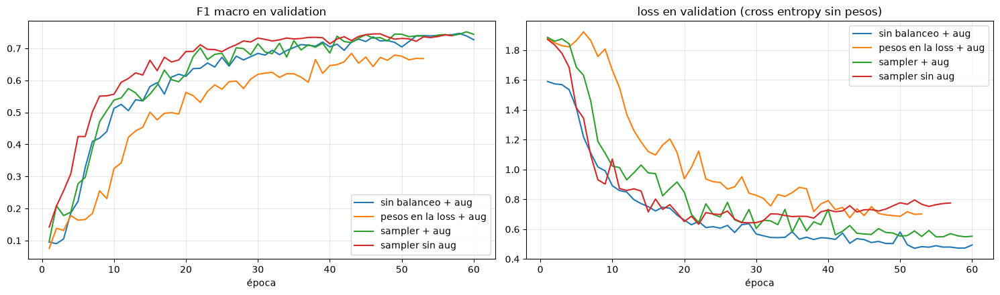

In [9]:
# Comparamos cuatro variantes con la misma arquitectura, hiperparámetros y semilla: sin balanceo, pesos en la loss
# y WeightedRandomSampler (las tres con augmentation), y el sampler sin augmentation.
EPOCAS_FINAL = 60
transform_sin_aug = transform_val
variantes = {
    "sin balanceo + aug":    dict(balanceo="ninguno", transform=transform_train),
    "pesos en la loss + aug": dict(balanceo="pesos", transform=transform_train),
    "sampler + aug":          dict(balanceo="sampler", transform=transform_train),
    "sampler sin aug":        dict(balanceo="sampler", transform=transform_sin_aug),
}
modelos, historiales, filas = {}, {}, []
for nombre, cfg in variantes.items():
    t0 = time.time()
    m, h, crit = entrenar(epocas=EPOCAS_FINAL, verbose=False, **cfg)
    _, acc, f1, pred = evaluar(m, loader_val, nn.CrossEntropyLoss())
    modelos[nombre], historiales[nombre] = m, h
    recall = np.diag(confusion_matrix(y_val, pred, normalize="true"))
    filas.append({"variante": nombre, "épocas entrenadas": len(h["f1_val"]), "mejor época": h["mejor_epoca"],
                  "accuracy val": acc, "F1 macro val": f1,
                  "loss val (mejor época)": h["loss_val"][h["mejor_epoca"] - 1],
                  **{f"recall {c}": r for c, r in zip(CLASES, recall)}})
    print(f"{nombre}: F1 macro {f1:.4f} | accuracy {acc:.4f} | {len(h['f1_val'])} épocas | {(time.time() - t0) / 60:.1f} min")
tabla_variantes = pd.DataFrame(filas).set_index("variante")
display(tabla_variantes.round(3).T)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for nombre, h in historiales.items():
    axes[0].plot(range(1, len(h["f1_val"]) + 1), h["f1_val"], label=nombre)
    axes[1].plot(range(1, len(h["loss_val"]) + 1), h["loss_val"], label=nombre)
axes[0].set_title("F1 macro en validation"); axes[1].set_title("loss en validation (cross entropy sin pesos)")
for ax in axes: ax.set_xlabel("época"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Comparando las cuatro variantes:

- Sin balanceo, el modelo tiene la mejor accuracy (0,832) pero sacrifica las clases chicas: el recall de disgusto es 0,45 y el de miedo 0,53. Es lo esperable si la red ve 17 caras felices por cada cara de miedo.
- Con el sampler, el F1 macro sube apenas (0,752 contra 0,747), pero el reparto entre clases cambia bastante: disgusto pasa a 0,68 de recall y miedo a 0,62, a cambio de bajar alegría (de 0,93 a 0,88) y seriedad (de 0,82 a 0,76). Como queremos un clasificador que reconozca todas las emociones y no solo las frecuentes, preferimos este reparto.
- Los pesos en la loss dieron claramente peor (F1 0,684) y la curva aprende más lento y con más ruido. Nuestra hipótesis es que, con un peso de 6,2 para miedo contra 0,37 para alegría, el gradiente de cada batch depende mucho de las pocas caras de miedo que le toquen, y eso lo vuelve más inestable. No lo probamos más a fondo.
- Sin augmentation, el F1 de la mejor época es parecido (0,745), pero en el gráfico de la derecha se ve que la loss de validation empieza a subir alrededor de la época 30. Es la señal típica de sobreajuste, y nuestra hipótesis es que la red se empieza a aprender las imágenes que el sampler le repite. En la mejor época, la loss de validation es 0,72 contra 0,55 con augmentation, y el recall de miedo cae a 0,49. Además, el augmentation de brillo, rotación y zoom debería ayudar con las fotos nuevas, que el dataset de validation no representa.

Hay que tomar estas diferencias con cuidado: es una sola corrida por variante, y diferencias del orden de 0,005 en el F1 pueden cambiar con otra semilla. Las que nos parecen más firmes son las grandes: el cambio en el recall de las clases chicas y el sobreajuste sin augmentation.

Nos quedamos con sampler + augmentation como modelo final.

In [10]:
FINAL = "sampler + aug"
modelo, hist = modelos[FINAL], historiales[FINAL]
criterio = nn.CrossEntropyLoss()
torch.save(modelo.state_dict(), "cnn_emociones.pt")
print(f"modelo final: {FINAL} | pesos de la época {hist['mejor_epoca']} de {len(hist['f1_val'])}")

modelo final: sampler + aug | pesos de la época 59 de 60


## 3. Evaluación del Modelo (2.5 puntos)

El modelo entrenado debe ser evaluado utilizando las siguientes métricas:

- **Accuracy**:
  - Reportar el valor final en el conjunto de validación.
  - Incluir una gráfica de evolución por época para entrenamiento y validación.

- **F1 Score Macro**:
  - Reportar el valor final en el conjunto de validación.
  - Incluir una gráfica de evolución por época para entrenamiento y validación.

- **Costo (Loss)**:
  - Mostrar una gráfica de evolución del costo por época para entrenamiento y validación.

- **Classification report**
  - Mostrar la precisión, recall y F1 score por cada clase usando `classification_report`

- **Matriz de confusión**:
  - Mostrar la matriz de confusión absoluta (valores enteros).
  - Mostrar la matriz de confusión normalizada (valores entre 0 y 1 por fila).

Se recomienda utilizar `scikit-learn` para calcular métricas como accuracy, F1 score, el Classification report y las matrices de confusión. Las visualizaciones pueden realizarse con `matplotlib` o `seaborn`.


Modelo final (pesos de la época 59) en validation:
  accuracy  = 0.8237
  F1 macro  = 0.7516
  loss      = 0.5492
En esa época, train vs validation: accuracy 0.8572 / 0.8237 | F1 macro 0.8579 / 0.7516 | loss 0.3999 / 0.5492
épocas en las que se redujo el learning rate: [41, 55]


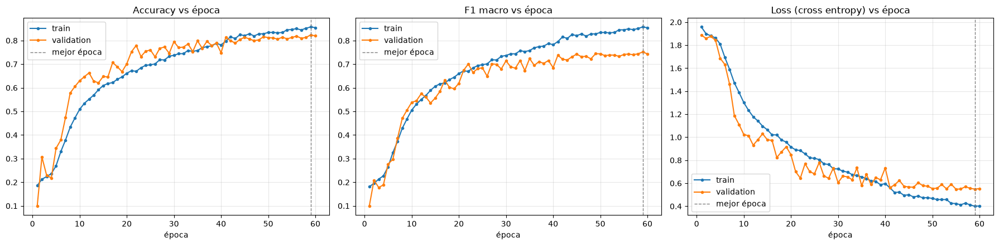

In [11]:
loss_val, acc_val, f1_val, pred_val = evaluar(modelo, loader_val, criterio)
print(f"Modelo final (pesos de la época {hist['mejor_epoca']}) en validation:")
print(f"  accuracy  = {acc_val:.4f}")
print(f"  F1 macro  = {f1_val:.4f}")
print(f"  loss      = {loss_val:.4f}")
b = hist["mejor_epoca"] - 1
print(f"En esa época, train vs validation: accuracy {hist['acc_train'][b]:.4f} / {hist['acc_val'][b]:.4f} | "
      f"F1 macro {hist['f1_train'][b]:.4f} / {hist['f1_val'][b]:.4f} | loss {hist['loss_train'][b]:.4f} / {hist['loss_val'][b]:.4f}")
print("épocas en las que se redujo el learning rate:", [e + 1 for e in range(1, len(hist["lr"])) if hist["lr"][e] < hist["lr"][e - 1]])

ep = range(1, len(hist["loss_train"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, clave, nombre in [(axes[0], "acc", "Accuracy"), (axes[1], "f1", "F1 macro"), (axes[2], "loss", "Loss (cross entropy)")]:
    ax.plot(ep, hist[f"{clave}_train"], label="train", marker=".")
    ax.plot(ep, hist[f"{clave}_val"], label="validation", marker=".")
    ax.axvline(hist["mejor_epoca"], color="gray", ls="--", lw=1, label="mejor época")
    ax.set_xlabel("época"); ax.set_title(f"{nombre} vs época"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [12]:
print(classification_report(y_val, pred_val, target_names=CLASES, digits=4))

              precision    recall  f1-score   support

     alegria     0.9571    0.8844    0.9193      1185
    disgusto     0.4395    0.6813    0.5343       160
       enojo     0.7158    0.8086    0.7594       162
       miedo     0.6133    0.6216    0.6174        74
    seriedad     0.8439    0.7632    0.8015       680
    sorpresa     0.7933    0.8632    0.8268       329
    tristeza     0.7895    0.8159    0.8025       478

    accuracy                         0.8237      3068
   macro avg     0.7361    0.7769    0.7516      3068
weighted avg     0.8403    0.8237    0.8293      3068



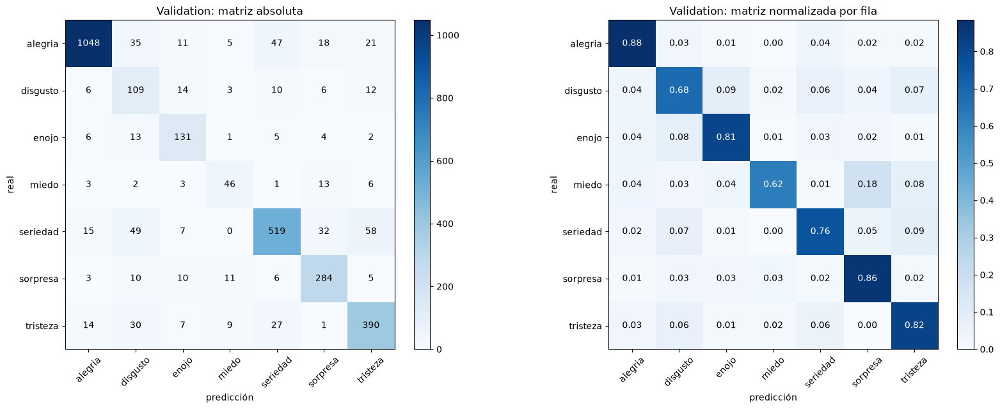

In [13]:
def graficar_confusion(y_real, y_pred, titulo=""):
    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
    for ax, normalizar, nombre in [(axes[0], None, "absoluta"), (axes[1], "true", "normalizada por fila")]:
        cm = confusion_matrix(y_real, y_pred, labels=range(len(CLASES)), normalize=normalizar)
        im = ax.imshow(cm, cmap="Blues")
        for i in range(len(CLASES)):
            for j in range(len(CLASES)):
                texto = f"{cm[i, j]:.2f}" if normalizar else f"{cm[i, j]:d}"
                ax.text(j, i, texto, ha="center", va="center", fontsize=10,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks(range(len(CLASES))); ax.set_yticks(range(len(CLASES)))
        ax.set_xticklabels(CLASES, rotation=45); ax.set_yticklabels(CLASES)
        ax.set_xlabel("predicción"); ax.set_ylabel("real"); ax.set_title(f"{titulo}matriz {nombre}")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout(); plt.show()

graficar_confusion(y_val, pred_val, "Validation: ")

Con los pesos de la época 59, el modelo final da 82,4% de accuracy y 0,752 de F1 macro en validation, con una loss de 0,549.

Mirando las curvas, en las primeras épocas validation va igual o incluso por encima de train (en accuracy, hasta cerca de la época 40). No es raro: las métricas de train se calculan sobre imágenes con augmentation, con dropout activo y sobre batches balanceados por el sampler, mientras que validation son las imágenes limpias con su distribución real. Por eso las curvas de train y validation no son del todo comparables entre sí. A partir de la época 30-40, train sigue subiendo y validation se aplana alrededor de 0,74-0,75 de F1. En la mejor época, train da 0,86 de F1 y 0,40 de loss, contra 0,75 y 0,55 en validation. Por lo que explicamos recién, no tomamos esa diferencia como una medida del sobreajuste. Lo que sí podemos decir es que validation dejó de mejorar mientras train seguía subiendo, y que la loss de validation no muestra una tendencia a subir, como sí pasaba en la variante sin augmentation. El salto que se ve en la curva de train cerca de la época 41 coincide con la primera reducción del learning rate: desde esa época se entrena con la mitad (y desde la 55, con la mitad otra vez).

Por clase, el classification report y las matrices de confusión muestran que:

- Alegría es la más fácil (F1 0,92): la sonrisa es muy característica y además es la clase con más datos.
- Sorpresa, tristeza y seriedad andan bien (F1 0,80-0,83) y enojo un poco menos (0,76).
- Miedo y disgusto son las más difíciles (F1 0,62 y 0,53). Son las clases con menos imágenes y las que más se parecen a otras.
- En proporción, la confusión más fuerte es miedo → sorpresa: el 18% de las caras de miedo se clasifican como sorpresa. Tiene mucho sentido, porque miedo y sorpresa tienen los ojos muy abiertos, las cejas levantadas y muchas veces la boca abierta. En cantidad absoluta, la confusión más grande es seriedad → tristeza, con 58 casos.
- Seriedad se confunde con tristeza (9%) y con disgusto (7%). Una cara neutra y una cara levemente triste o molesta se diferencian por detalles chicos.
- Disgusto tiene buen recall (0,68) pero precision baja (0,44): de las 248 imágenes que el modelo marca como disgusto, solo 109 lo son. El resto vienen sobre todo de seriedad (49), alegría (35) y tristeza (30). Creemos que es un efecto del sampler, que le muestra disgusto 2,4 veces más que su frecuencia real y empuja al modelo a predecirla de más.

Como extra, quisimos ver qué está mirando la red. En la notebook de CNN se pasaba una foto por una convolución con pesos al azar para ver qué salía. Acá hacemos lo mismo, pero con nuestro modelo ya entrenado: pasamos una cara de sorpresa de validation (que el modelo clasifica bien) y mostramos, para cada bloque, los 8 canales que más se activan.

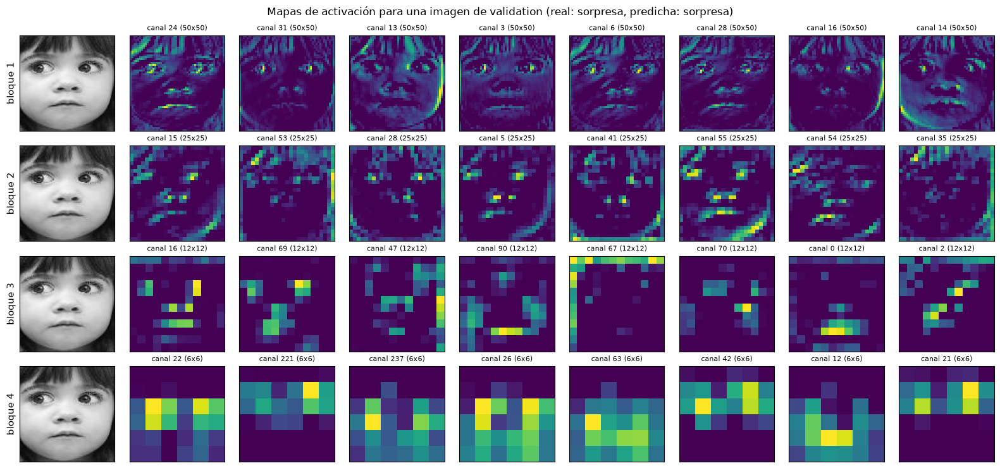

In [14]:
# ¿Qué está mirando la red? Pasamos una cara de validation por el modelo entrenado y mostramos,
# para cada bloque, los 8 canales que más se activan (la salida de cada bloque, después de la ReLU y el pooling).
k = int(np.where((y_val == CLASES.index("sorpresa")) & (pred_val == y_val))[0][0])
x = transform_val(imgs_val[k]).unsqueeze(0).to(device)

modelo.eval()
activaciones = []
with torch.no_grad():
    h = x
    for bloque in modelo.features:
        h = bloque(h)
        activaciones.append(h.squeeze(0).cpu().numpy())

fig, axes = plt.subplots(len(activaciones), 9, figsize=(16, 7.5))
for b, (fila, act) in enumerate(zip(axes, activaciones), start=1):
    fila[0].imshow(desnormalizar(x.squeeze(0).cpu()), cmap="gray")
    fila[0].set_ylabel(f"bloque {b}", fontsize=11)
    mas_activos = np.argsort(act.mean(axis=(1, 2)))[::-1][:8]
    for ax, canal in zip(fila[1:], mas_activos):
        ax.imshow(act[canal], cmap="viridis")
        ax.set_title(f"canal {canal} ({act.shape[1]}x{act.shape[2]})", fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"Mapas de activación para una imagen de validation (real: {CLASES[y_val[k]]}, predicha: {CLASES[pred_val[k]]})")
plt.tight_layout(); plt.show()

Se ve bastante bien lo que dicen las slides de "¿qué hay en los kernels?": cuanto más profunda la capa, más abstracto lo que detecta.

En el bloque 1 (50x50) los mapas todavía se parecen a la cara: marcan bordes y contrastes, como el contorno de los ojos, las fosas nasales, la línea de la boca, el flequillo y el borde de la cara. En el bloque 2 (25x25) la activación ya se concentra en puntos más chicos: las pupilas, la nariz y las comisuras de la boca. En los bloques 3 y 4 la resolución baja a 12x12 y 6x6 y ya no se reconoce la cara, pero sí se nota que distintos canales se especializan en distintas zonas. Varios se encienden más a la altura de los ojos, y otros, como el canal 12 del último bloque, más abajo, por la zona de la boca y el mentón. También aparecen canales que reaccionan al borde de la imagen o al pelo, que no tienen nada que ver con la emoción.

Igual hay que tomarlo con pinzas. Es una sola imagen, elegimos los canales por cuánto se activan y no por cuánto pesan en la decisión, y en el último bloque cada celda de 6x6 "ve" una zona grande de la cara. Así que no nos permite afirmar que la red ignora el fondo ni explicar por sí solo los errores del punto 4. Lo tomamos como una ilustración de cómo cambia la representación de un bloque a otro. El efecto del encuadre lo medimos de forma más directa comparando los puntos 4 y 5.

 ## 4. Prueba de Imágenes Nuevas (1 punto)
Subir al menos 12 imágenes personales de cualquier ratio o relación de aspecto (pueden usar fotos del rostro de ustedes, rostros de personas generadas por IA o imágenes stock de internet), que no formen parte del dataset de entrenamiento ni de validación. Tampoco vale usar imágenes de otro dataset, deben ser imágenes sueltas.

- Debe haber al menos una imagen para cada emoción.

- Aplicar el mismo pre-procesamiento que se usó para el dataset de validation durante el entrenamiento del modelo.

- Pasar las imágenes por el modelo entrenado y mostrar:

  - La imagen original
  - La imagen pre-procesada (mismas transformaciones que durante el entrenamiento)
  - El score asignado a cada clase (normalizado de 0 a 1 o de 0% a 100%)
  - La clase ganadora inferida por el modelo

- Redactar conclusiones preliminares

21 imágenes
{'alegria': 3, 'disgusto': 3, 'enojo': 3, 'miedo': 3, 'seriedad': 3, 'sorpresa': 3, 'tristeza': 3}


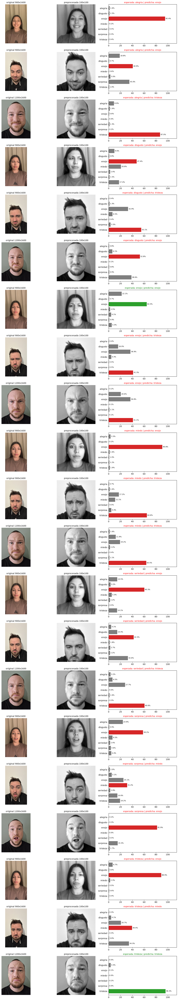

,imagen,esperada,predicha,score de la predicha,score de la esperada
0,alegria_azul.jpg,alegria,enojo,0.954,0.016
1,alegria_fede.jpg,alegria,enojo,0.409,0.188
2,alegria_nico.jpg,alegria,tristeza,0.870,0.089
3,disgusto_azul.jpg,disgusto,enojo,0.474,0.008
4,disgusto_fede.jpg,disgusto,tristeza,0.551,0.013
5,disgusto_nico.jpg,disgusto,enojo,0.528,0.061
6,enojo_azul.jpg,enojo,enojo,0.643,0.643
7,enojo_fede.jpg,enojo,tristeza,0.413,0.369
8,enojo_nico.jpg,enojo,tristeza,0.411,0.368
9,miedo_azul.jpg,miedo,enojo,0.908,0.016


aciertos: 2 de 21


In [15]:
# Nuestras imágenes: el nombre de cada archivo empieza con la emoción que quisimos mostrar (por ejemplo "alegria_fede.jpg").
# Si la carpeta no está (por ejemplo en Colab), se baja del zip que dejamos compartido en Drive.
CARPETA_PROPIAS = "imagenes_propias"
ID_ZIP_PROPIAS = "1R4OUUelbvjuxDMioyrp79H5A418s359y"
if not os.path.exists(CARPETA_PROPIAS):
    gdown.download(f"https://drive.google.com/uc?id={ID_ZIP_PROPIAS}", "imagenes_propias.zip", quiet=True)
    with zipfile.ZipFile("imagenes_propias.zip", "r") as z:
        z.extractall(".")

rutas_propias = sorted(f for f in glob.glob(os.path.join(CARPETA_PROPIAS, "*")) if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp")))
esperadas = [os.path.basename(f).split("_")[0] for f in rutas_propias]
print(f"{len(rutas_propias)} imágenes")
print(pd.Series(esperadas).value_counts().reindex(CLASES, fill_value=0).to_dict())

def predecir(imagen_pil):
    """Aplica el preprocesamiento de validation y devuelve el tensor y las probabilidades (softmax) de cada clase."""
    x = transform_val(imagen_pil.convert("RGB"))
    modelo.eval()
    with torch.no_grad():
        probs = F.softmax(modelo(x.unsqueeze(0).to(device)), dim=1).squeeze(0).cpu().numpy()
    return x, probs

def mostrar_prediccion(paneles, probs, esperada, axes):
    """paneles: lista de (imagen, título). Dibuja las imágenes y un gráfico de barras con el score de cada clase."""
    for ax, (img, titulo) in zip(axes[:-1], paneles):
        ax.imshow(img, cmap="gray" if np.ndim(img) == 2 else None); ax.set_title(titulo, fontsize=10); ax.axis("off")
    ganadora = int(np.argmax(probs))
    colores = ["tab:green" if (i == ganadora and CLASES[i] == esperada) else "tab:red" if i == ganadora else "tab:gray"
               for i in range(len(CLASES))]
    axes[-1].barh(CLASES, 100 * probs, color=colores)
    for i, p in enumerate(probs):
        axes[-1].text(100 * p + 1, i, f"{100 * p:.1f}%", va="center", fontsize=8)
    axes[-1].set_xlim(0, 115); axes[-1].invert_yaxis()
    axes[-1].set_title(f"esperada: {esperada} | predicha: {CLASES[ganadora]}", fontsize=10,
                       color="green" if CLASES[ganadora] == esperada else "red")

resultados_p4 = []
fig, axes = plt.subplots(len(rutas_propias), 3, figsize=(13, 3.2 * len(rutas_propias)),
                         gridspec_kw={"width_ratios": [1.3, 1, 1.6]})
for fila, (ruta, esperada) in zip(axes, zip(rutas_propias, esperadas)):
    original = Image.open(ruta).convert("RGB")
    x, probs = predecir(original)
    mostrar_prediccion([(original, f"original {original.size[0]}x{original.size[1]}"), (desnormalizar(x), "preprocesada 100x100")],
                       probs, esperada, fila)
    resultados_p4.append({"imagen": os.path.basename(ruta), "esperada": esperada, "predicha": CLASES[int(np.argmax(probs))],
                          "score de la predicha": probs.max(), "score de la esperada": probs[CLASES.index(esperada)]})
plt.tight_layout(); plt.show()

tabla_p4 = pd.DataFrame(resultados_p4)
display(tabla_p4.round(3))
print(f"aciertos: {(tabla_p4['esperada'] == tabla_p4['predicha']).sum()} de {len(tabla_p4)}")

Usamos 21 fotos nuestras: tres por emoción, una de cada uno (Azul, Fede y Nico), sacadas con el celular frente a una pared o una cortina y mirando a cámara. Les aplicamos exactamente el mismo preprocesamiento que a validation: grises, lado corto a 100, recorte central de 100x100 y normalización.

El resultado es muy malo: el modelo acierta 2 de las 21 (el enojo de Azul y la tristeza de Nico), y el score promedio que le asigna a la emoción correcta es de 17,2%. Además se equivoca con mucha seguridad: la alegría de Azul la clasifica como enojo con 95%, la alegría de Nico como tristeza con 87% y la sorpresa de Nico como enojo con 82%. Casi todo lo manda a enojo (11 de las 21) o a tristeza (8).

Lo más llamativo es que las predicciones parecen seguir más a la foto que a la cara que pusimos. Las siete fotos de Azul salen como enojo, sin importar la expresión, y cinco de las siete de Nico salen como tristeza. O sea que el acierto en el enojo de Azul es bastante casual: el modelo dice enojo para todas sus fotos.

Como conclusión preliminar, creemos que el problema no es tanto la expresión sino el encuadre. En la columna del medio se ve que, después del preprocesamiento, la cara ocupa más o menos la mitad del cuadro, con pelo, pared o cortina y ropa alrededor, mientras que en el dataset la cara llena toda la imagen y viene alineada. Los filtros de la red aprendieron a reconocer bocas y cejas al tamaño y en la posición en que aparecen en el dataset, y el augmentation que usamos solo cubre cambios chicos (zoom de ±10% y desplazamientos de 5%). Ante una cara a la mitad de tamaño y corrida, la red recibe algo muy distinto a lo que vio al entrenar. Eso podría explicar buena parte de los errores, aunque esta prueba sola no permite saber cuánto influye cada cosa: el fondo, la escala o la posición de la cara. También nos deja una advertencia sobre los scores: un score alto no garantiza que la predicción sea correcta, sobre todo con imágenes distintas a las del entrenamiento. Acá hay errores con más del 90%.

 ## 5. Prueba de Imágenes Nuevas con Pre-procesamiento Adicional (1 punto)
Las 12 imágenes del punto 4, ahora serán pasadas y recortadas por un algoritmo de detección de rostros. Usen el siguiente código para realizar un pre-procesamiento inicial de la imagen y ya luego aplican el pre-procesamiento que usaron al momento de entrenar el modelo.

- Pasar las imágenes por el modelo entrenado y mostrar:
  - La imagen original
  - La imagen recortada por el algoritmo
  - La imagen pre-procesada (mismas transformaciones del entrenamiento)
  - El score asignado a cada clase (normalizado de 0 a 1 o de 0% a 100%)
  - La clase esperada
  - La clase ganadora inferida por el modelo

- Analizar los casos en los que el modelo se equivoca e intentar identificar posibles causas, tales como:

  - Similitudes entre emociones.
  - Mezcla de 2 o más emociones en una misma expresión.

- Comparar los resultados con el punto 4 y redactar conclusiones finales.

**IMPORTANTE:** Ajusten los parámetros `scaleFactor`, `minNeighbors` y `minSize` según convenga para que la detección de rostros sea más efectiva y logre detectar rostros en sus 12 imágenes. No se queden necesariamente con los valores por defecto.

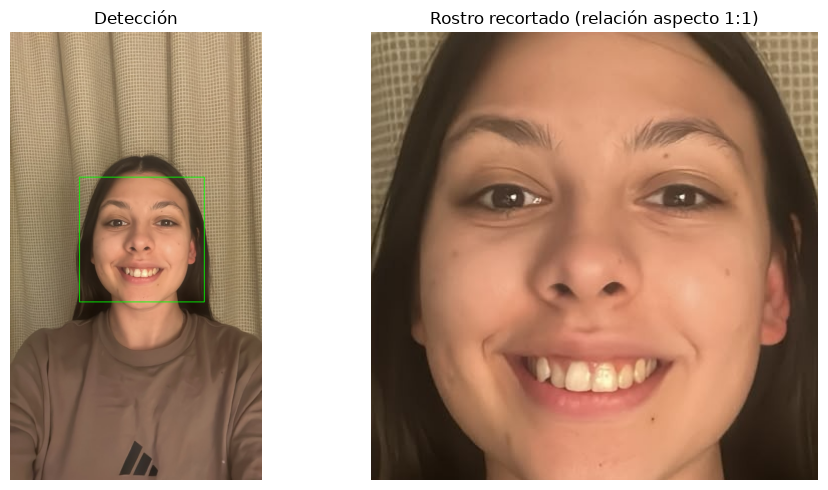

In [16]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

image_path = rutas_propias[0]   # una de nuestras imágenes, para ver el código original funcionando

image = cv2.imread(image_path)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=6, minSize=(30,30))

image_with_box = image.copy()
for (x, y, w, h) in faces:
    cv2.rectangle(image_with_box, (x, y), (x + w, y + h), (0, 255, 0), 2)

cropped_face_rgb = None
if len(faces) > 0:
    (x, y, w, h) = faces[0]
    center_x, center_y = x + w // 2, y + h // 2
    side = max(w, h)
    half_side = side // 2

    x1 = max(center_x - half_side, 0)
    y1 = max(center_y - half_side, 0)
    x2 = min(center_x + half_side, image.shape[1])
    y2 = min(center_y + half_side, image.shape[0])

    cropped_face = image[y1:y2, x1:x2]
    cropped_face_rgb = cv2.cvtColor(cropped_face, cv2.COLOR_BGR2RGB)

image_with_box_rgb = cv2.cvtColor(image_with_box, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image_with_box_rgb)
ax[0].set_title("Detección")
ax[0].axis('off')

if cropped_face_rgb is not None:
    ax[1].imshow(cropped_face_rgb)
    ax[1].set_title("Rostro recortado (relación aspecto 1:1)")
    ax[1].axis('off')
else:
    ax[1].text(0.5, 0.5, 'No se detectó rostro', horizontalalignment='center', verticalalignment='center')
    ax[1].axis('off')

plt.tight_layout()
plt.show()


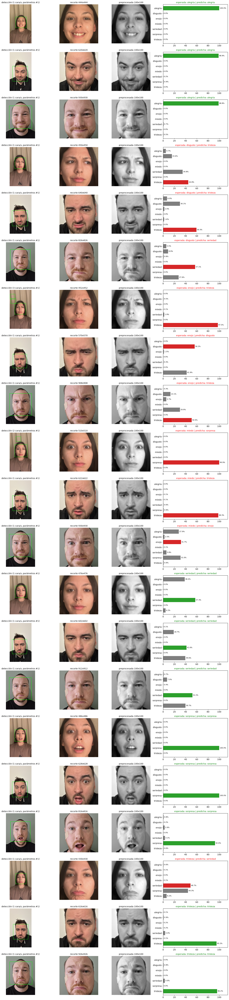

,imagen,esperada,predicha,score de la predicha,score de la esperada,segunda opción
0,alegria_azul.jpg,alegria,alegria,1.000,1.000,tristeza
1,alegria_fede.jpg,alegria,alegria,0.989,0.989,sorpresa
2,alegria_nico.jpg,alegria,alegria,0.988,0.988,seriedad
3,disgusto_azul.jpg,disgusto,tristeza,0.448,0.156,seriedad
4,disgusto_fede.jpg,disgusto,tristeza,0.593,0.301,disgusto
5,disgusto_nico.jpg,disgusto,seriedad,0.571,0.089,tristeza
6,enojo_azul.jpg,enojo,tristeza,0.975,0.000,seriedad
7,enojo_fede.jpg,enojo,disgusto,0.562,0.015,tristeza
8,enojo_nico.jpg,enojo,tristeza,0.509,0.057,seriedad
9,miedo_azul.jpg,miedo,sorpresa,0.999,0.000,alegria


rostros detectados: 21 de 21
aciertos: 11 de 21


In [17]:
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Mismo procedimiento que el código de la consigna, como función. Cambios: si aparece más de una cara nos quedamos
# con la más grande, y si con los parámetros elegidos no se detecta nada probamos con otros más permisivos.
PARAMETROS_HAAR = [
    dict(scaleFactor=1.05, minNeighbors=6, minSize=(60, 60)),
    dict(scaleFactor=1.05, minNeighbors=4, minSize=(40, 40)),
    dict(scaleFactor=1.03, minNeighbors=3, minSize=(30, 30)),
]

def recortar_rostro(image_path):
    image = cv2.imread(image_path)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    for intento, params in enumerate(PARAMETROS_HAAR):
        lado_min = min(gray.shape)
        params = dict(params, minSize=(max(params["minSize"][0], lado_min // 10),) * 2)   # caras chicas en fotos grandes suelen ser falsos positivos
        faces = face_cascade.detectMultiScale(gray, **params)
        if len(faces) > 0:
            break
    image_with_box = image.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(image_with_box, (x, y), (x + w, y + h), (0, 255, 0), max(2, lado_min // 150))
    cropped_face_rgb = None
    if len(faces) > 0:
        (x, y, w, h) = max(faces, key=lambda f: f[2] * f[3])
        center_x, center_y = x + w // 2, y + h // 2
        half_side = max(w, h) // 2
        x1, y1 = max(center_x - half_side, 0), max(center_y - half_side, 0)
        x2, y2 = min(center_x + half_side, image.shape[1]), min(center_y + half_side, image.shape[0])
        cropped_face_rgb = cv2.cvtColor(image[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
    return cv2.cvtColor(image_with_box, cv2.COLOR_BGR2RGB), cropped_face_rgb, len(faces), intento

resultados_p5 = []
fig, axes = plt.subplots(len(rutas_propias), 4, figsize=(16, 3.2 * len(rutas_propias)),
                         gridspec_kw={"width_ratios": [1.3, 1, 1, 1.6]})
for fila, (ruta, esperada) in zip(axes, zip(rutas_propias, esperadas)):
    con_caja, recorte, n_caras, intento = recortar_rostro(ruta)
    if recorte is None:
        for ax in fila: ax.axis("off")
        fila[0].imshow(con_caja); fila[0].set_title("no se detectó rostro")
        continue
    x, probs = predecir(Image.fromarray(recorte))
    mostrar_prediccion([(con_caja, f"detección ({n_caras} cara/s, parámetros #{intento + 1})"),
                        (recorte, f"recorte {recorte.shape[1]}x{recorte.shape[0]}"),
                        (desnormalizar(x), "preprocesada 100x100")], probs, esperada, fila)
    resultados_p5.append({"imagen": os.path.basename(ruta), "esperada": esperada, "predicha": CLASES[int(np.argmax(probs))],
                          "score de la predicha": probs.max(), "score de la esperada": probs[CLASES.index(esperada)],
                          "segunda opción": CLASES[int(np.argsort(probs)[-2])]})
plt.tight_layout(); plt.show()

tabla_p5 = pd.DataFrame(resultados_p5)
display(tabla_p5.round(3))
print(f"rostros detectados: {len(tabla_p5)} de {len(rutas_propias)}")
print(f"aciertos: {(tabla_p5['esperada'] == tabla_p5['predicha']).sum()} de {len(tabla_p5)}")

In [18]:
# Comparación punto 4 (imagen entera) vs punto 5 (rostro recortado)
comparacion = tabla_p4[["imagen", "esperada", "predicha", "score de la esperada"]].merge(
    tabla_p5[["imagen", "predicha", "score de la esperada"]], on="imagen", suffixes=(" (p4)", " (p5)"), how="left")
display(comparacion.round(3))
print(f"aciertos punto 4: {(comparacion['esperada'] == comparacion['predicha (p4)']).sum()} | "
      f"punto 5: {(comparacion['esperada'] == comparacion['predicha (p5)']).sum()} de {len(comparacion)}")
print(f"score medio de la clase esperada: punto 4 {comparacion['score de la esperada (p4)'].mean():.1%} | "
      f"punto 5 {comparacion['score de la esperada (p5)'].mean():.1%}")

,imagen,esperada,predicha (p4),score de la esperada (p4),predicha (p5),score de la esperada (p5)
0,alegria_azul.jpg,alegria,enojo,0.016,alegria,1.000
1,alegria_fede.jpg,alegria,enojo,0.188,alegria,0.989
2,alegria_nico.jpg,alegria,tristeza,0.089,alegria,0.988
3,disgusto_azul.jpg,disgusto,enojo,0.008,tristeza,0.156
4,disgusto_fede.jpg,disgusto,tristeza,0.013,tristeza,0.301
5,disgusto_nico.jpg,disgusto,enojo,0.061,seriedad,0.089
6,enojo_azul.jpg,enojo,enojo,0.643,tristeza,0.000
7,enojo_fede.jpg,enojo,tristeza,0.369,disgusto,0.015
8,enojo_nico.jpg,enojo,tristeza,0.368,tristeza,0.057
9,miedo_azul.jpg,miedo,enojo,0.016,sorpresa,0.000


aciertos punto 4: 2 | punto 5: 11 de 21
score medio de la clase esperada: punto 4 17.2% | punto 5 47.7%


El detector encontró la cara en las 21 imágenes con el primer juego de parámetros, así que no hizo falta usar los de respaldo. Respecto de los valores del código original cambiamos dos cosas:

- Bajamos `scaleFactor` de 1,1 a 1,05. Así el detector prueba más tamaños intermedios de cara, con lo que es menos probable que se saltee el tamaño justo. Es más lento, pero con 21 imágenes no importa.
- Subimos `minSize` a la décima parte del lado corto de la imagen (como mínimo 60 píxeles). En fotos grandes como las nuestras, una "cara" de 30x30 es casi seguro un falso positivo.

`minNeighbors` quedó en 6. Igual aparecieron falsos positivos: en el enojo y el miedo de Azul, el detector también marcó "caras" en la textura cuadriculada de la cortina (se ven los recuadros de más en la primera columna). Por eso, cuando hay más de una detección nos quedamos con la más grande [2], y en los dos casos fue la cara real.

Con el rostro recortado, el modelo pasa de 2 a 11 aciertos sobre 21, y el score promedio de la clase correcta sube de 17,2% a 47,7%. Son los mismos pesos y las mismas fotos. Lo que cambió es el recorte, que a la vez agranda la cara, la centra y saca casi todo el fondo, o sea que la entrada se parece mucho más a lo que la red vio en el entrenamiento. No separamos cuál de esas tres cosas pesa más.

La mejora no es en todas las fotos: el recorte corrige diez errores y pierde un acierto, el enojo de Azul (que pasa de enojo a tristeza). En el punto 4 ese acierto era parte del patrón en el que las siete fotos de Azul salían como enojo, así que tampoco podemos decir que ahí el modelo hubiera reconocido bien la expresión. De las 21 fotos, 10 pasan de mal a bien, 1 sigue bien (la tristeza de Nico), 1 pasa de bien a mal y 9 siguen mal.

Por emoción, acierta las tres fotos de alegría y las tres de sorpresa, todas con más de 92%, y las tres de seriedad, aunque con poca seguridad (entre 42% y 57%). En tristeza acierta dos de tres (Fede y Nico, con más de 95%). Falla las tres fotos de disgusto, las tres de enojo y las tres de miedo. Mirando los errores de a uno:

- Miedo (Azul) → sorpresa con 99,9%. Ojos muy abiertos y cejas levantadas, con la boca cerrada. Es justamente la confusión más fuerte que vimos en validation (miedo → sorpresa), y en esta foto las dos emociones se distinguen por muy poco.
- Miedo (Fede) → tristeza con 98%. En la foto las cejas están levantadas y juntas en el centro y la boca apenas abierta. Ese gesto de cejas es el típico de la tristeza, así que nos parece que la cara mezcla las dos emociones; mirándola de nuevo, nos salió más una cara de preocupación que de miedo. Encima, en el dataset las caras de miedo suelen tener la boca muy abierta, casi gritando.
- Miedo (Nico) → enojo 32%, sorpresa 31%, alegría 28%. El modelo no se decide: los ojos muy abiertos se parecen a sorpresa, pero la boca está cerrada y tensa.
- Enojo (Azul) → tristeza con 97,5%. El ceño está fruncido, pero la boca va en trompa hacia abajo, y esa boca es muy de tristeza. Es otra cara que mezcla dos emociones.
- Enojo (Fede) → disgusto 56%, tristeza 42%. El ceño está fruncido, pero la boca está en trompa, y eso se parece más a un gesto de asco o de berrinche. En el dataset el enojo suele venir con los dientes a la vista o la boca abierta.
- Enojo (Nico) → tristeza 51%, seriedad 30%. Ceño fruncido con la boca neutra: un enojo contenido queda a mitad de camino entre una cara neutra y una triste.
- Disgusto (Azul) → tristeza 45%, seriedad 35%, disgusto 16%. Mira de costado con la boca torcida; más que asco, transmite desconfianza.
- Disgusto (Fede) → tristeza 59%, con disgusto en segundo lugar (30%). La nariz arrugada y el labio levantado son señales de disgusto, y puede ser que por eso aparezca como segunda opción. Es el error más "cercano".
- Disgusto (Nico) → seriedad 57%. Es una expresión sutil, casi neutra; mirándola de nuevo, a nosotros también nos cuesta leerla como disgusto.
- Tristeza (Azul) → seriedad 49%, sorpresa 44%. La boca hace puchero, pero los ojos están bien abiertos y las cejas quietas; puede ser que por eso el modelo dude entre una cara neutra y una sorprendida.

En parte, los errores coinciden con lo que vimos en validation. Las tres emociones que falla siempre incluyen a las dos de menor F1 (disgusto 0,53 y miedo 0,62), y se repiten algunas confusiones, como miedo → sorpresa en la foto de Azul o la zona gris entre seriedad y tristeza. Pero no todas: en validation miedo se va sobre todo a sorpresa, y acá las otras dos fotos de miedo terminan en tristeza y enojo; y enojo → tristeza, que en validation pasa en 2 de 162 casos, aparece en dos de nuestras tres fotos de enojo. Eso es compatible con el cambio de tipo de imagen (fotos nuestras, con otra luz y otra cámara) y con lo ambiguas que son algunas de nuestras caras, aunque con 21 fotos no podemos separar una causa de la otra.

También nos llamó la atención que, con el recorte, los aciertos y los errores se repiten en las tres personas para la misma emoción: alegría, sorpresa y seriedad salen bien en los tres, y disgusto, enojo y miedo salen mal en los tres. Es compatible con que, una vez recortada la cara, pese más la emoción y cómo la actuamos que la persona (por ejemplo, la curita de Nico no le impidió acertar alegría, sorpresa, seriedad y tristeza). En el punto 4 pasaba lo contrario: las predicciones seguían más a la foto que a la expresión. Igual, con tres personas y fotos sacadas en lugares distintos, no podemos separar del todo esos efectos. Creemos que también influyen las similitudes entre emociones (miedo/sorpresa, enojo/disgusto, seriedad/tristeza) y que varias de nuestras caras mezclan dos emociones. Tampoco somos actores: nuestras caras de miedo, enojo y disgusto son bastante más suaves que las del dataset.

Conclusiones finales:

- Comparando con el punto 4, el preprocesamiento de la entrada pesa muchísimo: con los mismos pesos pasamos de 2 a 11 aciertos solo por recortar la cara como en el dataset. Si quisiéramos usar este clasificador con fotos reales, la detección (y idealmente la alineación) del rostro tiene que ser parte del pipeline, no un extra.
- La CNN entrenada desde cero llega a 82% de accuracy y 0,75 de F1 macro en validation, y en nuestras fotos bien recortadas reconoció las expresiones más marcadas: alegría y sorpresa en las tres personas, con más de 92%. Le cuestan las emociones con pocos ejemplos y las que se parecen entre sí.
- 21 fotos de tres personas, con expresiones actuadas, no alcanzan para sacar conclusiones estadísticas. Sirven para ver patrones, pero un 11 de 21 podría ser muy distinto con otras fotos. Por otro lado, la cascada de Haar que usamos está pensada para caras de frente, así que con fotos de perfil o muy inclinadas es probable que no detecte la cara y el pipeline falle antes de llegar al modelo. Y, como vimos con la cortina, también puede detectar caras donde no las hay.
- Como mejoras, probaríamos un augmentation de escala y recorte más agresivo (por ejemplo `RandomResizedCrop` con un rango más amplio) para que el modelo dependa menos del encuadre, y conseguir más ejemplos de disgusto y miedo, que son las clases que más fallan.

#### Referencias

[1] Documentación de PyTorch, `WeightedRandomSampler`: https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.WeightedRandomSampler

[2] Documentación de OpenCV, Cascade Classifier (`detectMultiScale` y sus parámetros): https://docs.opencv.org/4.x/db/d28/tutorial_cascade_classifier.html

[3] Documentación de PyTorch, `ReduceLROnPlateau`: https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html